# Chapter 1 — Burgers (sawtooth): TD-PINs vs Vanilla PINs vs Analytical — **KAN backbone**

**Case:** 1-D viscous Burgers, sawtooth analytic solution (Hopf–Cole) on $[0, 2\pi]$,
$\;u_t + u\,u_x = \nu\,u_{xx}$.

**Same experiment as `burgers_tdpinns_vs_vanilla_sawtooth.ipynb`, but the underlying architecture is a
Kolmogorov–Arnold Network (KAN, `pykan`) instead of an MLP.** Both methods share the KAN backbone,
collocation, weights, and lr schedule — only `PINArchitecture('MLP', ...)` becomes
`PINArchitecture('KAN', ...)`.

- **TD-PINs** — one KAN per time level, **Crank–Nicolson** stepping ($u(x)$ per step).
- **Vanilla PINs** (Raissi et al.) — a single space–time KAN $u(t,x)$ over the whole slab.
- **Analytical** — the Hopf–Cole sawtooth, used as ground truth.

**What we report (identical to the MLP notebook):**
1. **All error norms** $L_1$, $L_2$, $L_\infty$ vs the analytical solution, per time level.
2. **Conservation diagnostics** — mass $M(t)=\int u\,dx$ conserved; energy $E(t)=\int u^2\,dx$ dissipates
   ($dE/dt=-2\nu\int u_x^2\,dx\le 0$).
3. **Spectral test** — FFT in $x$ against the analytical solution, error per frequency band
   (DC / low / mid / high); the shock lives in the high modes.

> **KAN note:** `pykan` creates a `./model` checkpoint dir on every `PINArchitecture('KAN', ...)` call;
> we clear it between experiments. KAN training is markedly slower than MLP, so the per-method epoch
> budgets below are smaller than the MLP notebook's.

In [1]:
import sys, os, time, shutil

ROOT = '/home/df.gomezb/Tesis'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    compute_metrics, collocation_uniform, collocation_mean_residual
)

torch.manual_seed(0)
np.random.seed(0)

# distinct serif / Computer-Modern look for every figure
plt.rcParams.update({
    'font.family'     : 'serif',
    'font.serif'      : ['DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size'       : 12,
    'axes.titlesize'  : 13,
    'axes.labelsize'  : 12,
    'legend.fontsize' : 9,
})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch:', torch.__version__, '| device:', DEVICE)

# marker / colour convention for the two methods (KAN backbone)
METHODS = {'TD-PINs': ('o', 'tab:blue'), 'Vanilla': ('s', 'tab:orange')}

FIGDIR = 'figs'
os.makedirs(FIGDIR, exist_ok=True)

def clear_kan_cache():
    """pykan writes a ./model checkpoint dir on every KAN construction — keep it from piling up."""
    shutil.rmtree('./model', ignore_errors=True)

torch: 2.12.1+cu130 | device: cuda


## 1. Problem setup — sawtooth analytic solution

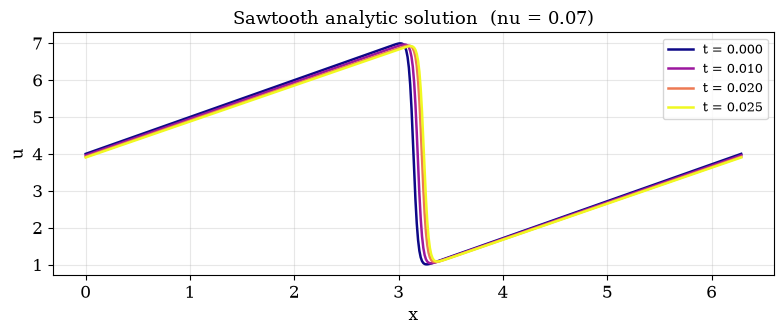

In [2]:
NU     = 0.07
X0, XF = 0.0, 2 * np.pi

def toothsaw(t, x):
    """Hopf-Cole analytic solution for viscous Burgers on [0, 2pi]."""
    x  = np.asarray(x, dtype=float)
    nu = NU
    c  = 4 * nu * (t + 1)
    a  = (-4*t + x)**2           / c
    b  = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x)            * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * nu * num / den + 4

x_plot = np.linspace(X0, XF, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.plasma
for i, t in enumerate([0.0, 0.01, 0.02, 0.025]):
    ax.plot(x_plot, toothsaw(t, x_plot), color=cmap(i / 3), lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Sawtooth analytic solution  (nu = 0.07)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Experiment configuration

TD-PINs uses a spatial-only KAN $u(x)$ per step (`layers[0]=1`); Vanilla uses a space–time KAN
$u(t,x)$ (`layers[0]=2`). Both share the grid/spline order, collocation, and the lr schedule.

**KAN-specific kwargs:**
- `grid_size` — number of spline grid intervals per activation.
- `spline_order` — B-spline degree ($k$).
- `grid_range` — extent of the spline knots; set to each net's **input domain** so the splines cover
  the data. TD ($u(x)$) uses $[X_0, X_F]$; Vanilla ($u(t,x)$) shares one range across both inputs, so
  we use $[0, X_F]$ which contains both $t\in[0,T]$ and $x\in[0,2\pi]$.
- `grid_eps` — grid spacing rule: `0` = fully adaptive (knots placed at sample quantiles), `1` =
  uniform knots. We use a small non-zero value (`0.05`) for a mostly-adaptive grid that still keeps a
  uniform-spacing floor.

In [ ]:
# KAN backbones — grid_range set to the input domain, grid_eps non-zero (mostly adaptive grid)
GRID_SIZE, SPLINE_ORDER, GRID_EPS = 20, 3, 0.05

PARAMS_TD  = {'layers': (1, 16, 16, 1), 'grid_size': GRID_SIZE, 'spline_order': SPLINE_ORDER,
              'grid_range': (X0, XF),  'grid_eps': GRID_EPS}   # u(x)    over x in [X0, XF]
PARAMS_VAN = {'layers': (2, 16, 16, 1), 'grid_size': GRID_SIZE, 'spline_order': SPLINE_ORDER,
              'grid_range': (0.0, XF), 'grid_eps': GRID_EPS}   # u(t, x) over [0, XF] (covers t and x)

DT     = 0.005
T_END  = 0.025
NT     = round(T_END / DT)
times  = [k * DT for k in range(NT + 1)]

# optimisation (shared schedule)
LR, MAX_LR, MIN_LR = 1e-2, 1e-2, 1e-6
_norm      = (15**2 + 5**2 + 1**2) ** 0.5
IC_WEIGHT  = 15.0 / _norm
BC_WEIGHT  = 5.0  / _norm
PDE_WEIGHT = 1.0  / _norm
N_COLLOC   = 500
N_EVAL     = 1000

# KAN is much slower per epoch than MLP — smaller budgets than the MLP notebook.
TD_EPOCHS,  TD_TOL  = 8000,  1e-2     # CN per-step
VAN_EPOCHS, VAN_TOL = 20000, 1e-2     # space-time fit

print(f'{NT} steps, dt={DT}, T={T_END}')
print(f'KAN: grid_size={GRID_SIZE}, spline_order={SPLINE_ORDER}, grid_eps={GRID_EPS}')
print(f'  TD  grid_range={PARAMS_TD["grid_range"]}')
print(f'  VAN grid_range={PARAMS_VAN["grid_range"]}')

5 steps, dt=0.005, T=0.025
KAN: grid_size=20, spline_order=3, grid_eps=0.05
  TD  grid_range=(0.0, 6.283185307179586)
  VAN grid_range=(0.0, 6.283185307179586)


## 3. IC / BC, residuals, exact evaluator, time-slice wrapper

- **TD residual** (Crank–Nicolson): $\frac{u-u^{t-1}}{\Delta t} + \tfrac12[S(u)+S(u^{t-1})]$, $S(w)=w w_x-\nu w_{xx}$.
- **Vanilla residual**: the strong PDE residual $u_t + u u_x - \nu u_{xx}$ with $u_t$ from autograd in $t$.
- **`TimeSlice`** wraps the Vanilla $u(t,x)$ KAN into a spatial-only $u(x)$ at a fixed $t$, so the same
  `compute_metrics` path works for both methods.

The residual functions are **unchanged** from the MLP notebook — KAN is autograd-compatible, so the
same derivative chain works.

In [4]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = toothsaw(0, x_ic_np)
x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

u_bc_val = float(toothsaw(0, X0))
x_bc = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc = torch.full((2, 1), u_bc_val, dtype=torch.float32)

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

def td_residual(u, u_prev, x, dt, nu):
    """TD-PINs Crank-Nicolson residual."""
    def S(w):
        w_x  = torch.autograd.grad(w.sum(),   x, create_graph=True)[0]
        w_xx = torch.autograd.grad(w_x.sum(), x, create_graph=True)[0]
        return w * w_x - nu * w_xx
    return (u - u_prev.detach()) / dt + 0.5 * (S(u) + S(u_prev).detach())

def vanilla_residual(u, t, x, nu):
    """Vanilla strong-form Burgers residual u_t + u u_x - nu u_xx."""
    u_t  = torch.autograd.grad(u.sum(),   t, create_graph=True)[0]
    u_x  = torch.autograd.grad(u.sum(),   x, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x.sum(), x, create_graph=True)[0]
    return u_t + u * u_x - nu * u_xx

loss_td  = PINLossFunction([x_dim], td_residual)
loss_van = PINLossFunction([x_dim], vanilla_residual)

def exact_fn(t, x_pts):
    u = toothsaw(t, x_pts.detach().cpu().numpy().ravel())
    return torch.tensor(u, dtype=torch.float32, device=x_pts.device).unsqueeze(1)

class TimeSlice(nn.Module):
    """Expose a space-time net u(t,x) as a spatial-only net u(x) at fixed t."""
    def __init__(self, net, t):
        super().__init__(); self.net = net; self.t = float(t)
    def forward(self, x):
        tcol = torch.full((x.shape[0], 1), self.t, device=x.device, dtype=x.dtype)
        return self.net(torch.cat([tcol, x], dim=1))

## 4. Train TD-PINs (Crank–Nicolson) — KAN per step

In [ ]:
clear_kan_cache()
torch.manual_seed(0); np.random.seed(0)
net_td = PINArchitecture('KAN', PARAMS_TD)
trainer_td = PINTrainer(
    net=net_td, scheme='TD-PINNS', loss_fn=loss_td, spatial_dims=[x_dim],
    epochs=TD_EPOCHS, dt=DT, lr=LR, max_lr=MAX_LR, min_lr=MIN_LR, tolerance=TD_TOL,
    ic_weight=IC_WEIGHT, bc_weight=BC_WEIGHT, pde_weight=PDE_WEIGHT,
    collocation_fn=collocation_mean_residual, device=DEVICE, verbose=True, log_every=100,
)
t0 = time.perf_counter()
nets_td = trainer_td.fit(x_ic=x_ic, u_ic=u_ic, x_bc=x_bc, u_bc=u_bc, T=T_END, nu=NU)
wall_td = time.perf_counter() - t0
epochs_td = sum(h['epochs'] for h in trainer_td.step_history[1:])
print(f'TD-PINs (KAN) done | epochs(PDE steps)={epochs_td} | wall {wall_td:.1f}s')

checkpoint directory created: ./model
saving model version 0.0
=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] epoch   100 | loss 4.3963e-03
  [step 0 / IC] epoch   200 | loss 2.6942e-04
  [step 0 / IC] epoch   300 | loss 5.9656e-05
  [step 0 / IC] epoch   400 | loss 3.1665e-05
  [step 0 / IC] epoch   500 | loss 1.9675e-05
  [step 0 / IC] epoch   600 | loss 1.3079e-05
  [step 0 / IC] converged at epoch 674 | loss 9.9778e-06
=== TD-PINNs | step 1/5  (t = 0.005) ===
  [step 1] epoch   100 | loss 9.1655e+00
  [step 1] epoch   200 | loss 7.7696e-01
  [step 1] epoch   300 | loss 2.3234e-01
  [step 1] epoch   400 | loss 1.0830e-01
  [step 1] epoch   500 | loss 2.9733e-02
  [step 1] epoch   600 | loss 1.3534e-02
  [step 1] epoch   700 | loss 1.3183e-02
  [step 1] epoch   800 | loss 1.1573e-02
  [step 1] epoch   900 | loss 1.0959e-02
  [step 1] epoch  1000 | loss 7.5695e-03
  [step 1] epoch  1100 | loss 6.8943e-03
  [step 1] epoch  1200 | loss 1.4305e-02
  [step 1] epoch  1300 | 

## 5. Train Vanilla PINs (single space–time KAN)

In [ ]:
clear_kan_cache()
torch.manual_seed(0); np.random.seed(0)
net_van = PINArchitecture('KAN', PARAMS_VAN)
trainer_van = PINTrainer(
    net=net_van, scheme='VANILLA', loss_fn=loss_van, spatial_dims=[x_dim],
    epochs=VAN_EPOCHS, lr=LR, max_lr=MAX_LR, min_lr=MIN_LR, tolerance=VAN_TOL,
    ic_weight=IC_WEIGHT, bc_weight=BC_WEIGHT, pde_weight=PDE_WEIGHT,
    collocation_fn=collocation_uniform, device=DEVICE, verbose=True, log_every=2000,
)
t0 = time.perf_counter()
vanilla_net = trainer_van.fit(x_ic=x_ic, u_ic=u_ic, x_bc=x_bc, u_bc=u_bc, T=T_END, nu=NU)[0]
wall_van = time.perf_counter() - t0
epochs_van = trainer_van.step_history[-1]['epochs']
print(f'Vanilla (KAN) done | epochs={epochs_van} | wall {wall_van:.1f}s')

## 6. Evaluate both methods — all error norms ($L_1$, $L_2$, $L_\infty$)

Both methods are reduced to a list of per-time spatial nets (Vanilla via `TimeSlice`), evaluated with the
framework's `compute_metrics`; $L_1$ (mean-abs) is added per level.

In [ ]:
vanilla_slices = [TimeSlice(vanilla_net, t).to(DEVICE) for t in times]

def add_L1(df, slice_nets):
    xg = torch.linspace(X0, XF, N_EVAL).unsqueeze(1).to(DEVICE)
    l1 = []
    for t, net in zip(times, slice_nets):
        net.eval()
        with torch.no_grad():
            up = net(xg)
            if up.dim() == 1:
                up = up.unsqueeze(1)
        l1.append(float((up - exact_fn(t, xg)).abs().mean()))
    df['L1'] = l1
    return df

results = {
    'TD-PINs': {'slices': nets_td,        'epochs': epochs_td,  'wall': wall_td},
    'Vanilla': {'slices': vanilla_slices, 'epochs': epochs_van, 'wall': wall_van},
}
for m, r in results.items():
    df = compute_metrics(r['slices'], times, [x_dim], n_eval=N_EVAL,
                         exact_fn=exact_fn, device=DEVICE)
    r['df'] = add_L1(df, r['slices'])

rows = []
for m, r in results.items():
    d = r['df']
    rows.append({'method': m, 'epochs': r['epochs'],
                 'mean_L1': d['L1'].mean(), 'mean_L2': d['L2'].mean(), 'mean_Linf': d['Linf'].mean(),
                 'final_L1': d['L1'].iloc[-1], 'final_L2': d['L2'].iloc[-1], 'final_Linf': d['Linf'].iloc[-1],
                 'wall_s': r['wall']})
summary = pd.DataFrame(rows).set_index('method')
pd.set_option('display.float_format', '{:.4e}'.format)
print('=== TD-PINs vs Vanilla (KAN) — error summary (vs analytical) ===')
print(summary.to_string())

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (label, col) in zip(axes, [(r'$L_1$', 'L1'), (r'$L_2$', 'L2'), (r'$L_\infty$', 'Linf')]):
    for m, r in results.items():
        mk, c = METHODS[m]
        ax.semilogy(times, r['df'][col].values, '-', marker=mk, ms=6, lw=1.5, color=c, label=m)
    ax.set_xlabel('t'); ax.set_ylabel(f'{label} error vs exact')
    ax.set_title(f'{label} error per time level')
    ax.grid(True, which='both', alpha=0.3); ax.legend()
fig.suptitle('Burgers sawtooth (KAN) — TD-PINs vs Vanilla (error vs analytical)', fontsize=14)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'burgers_kan_methods_errors.pdf'), bbox_inches='tight')
print('saved ->', os.path.join(FIGDIR, 'burgers_kan_methods_errors.pdf'))
plt.show()

## 7. Conservation — mass $\int u\,dx$ and energy $\int u^2\,dx$

Mass should stay flat (conserved analytically: $\int u\,dx = 4\cdot 2\pi$). Energy must **decrease**
monotonically (viscous dissipation $dE/dt = -2\nu\int u_x^2\,dx \le 0$). The analytical curve is the
reference; a good method tracks it.

In [ ]:
df_ref = results['TD-PINs']['df']   # exact_mass / exact_energy are method-independent

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# mass conservation
ax = axes[0]
ax.plot(times, df_ref['exact_mass'].values, 'k-', lw=2.4, label='analytical')
for m, r in results.items():
    mk, c = METHODS[m]
    ax.plot(times, r['df']['mass'].values, '-', marker=mk, ms=6, lw=1.5, color=c, label=m)
ax.set_xlabel('t'); ax.set_ylabel(r'mass  $\int u\,dx$')
ax.set_title('Mass conservation (flat = conserved)')
ax.grid(alpha=0.3); ax.legend()

# energy dissipation
ax = axes[1]
ax.plot(times, df_ref['exact_energy'].values, 'k-', lw=2.4, label='analytical')
for m, r in results.items():
    mk, c = METHODS[m]
    ax.plot(times, r['df']['energy'].values, '-', marker=mk, ms=6, lw=1.5, color=c, label=m)
ax.set_xlabel('t'); ax.set_ylabel(r'energy  $\int u^2\,dx$')
ax.set_title(r'Energy dissipation ($dE/dt \leq 0$, decreasing)')
ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'burgers_kan_methods_conservation.pdf'), bbox_inches='tight')
print('saved ->', os.path.join(FIGDIR, 'burgers_kan_methods_conservation.pdf'))
plt.show()

# numeric check
print('\nanalytical mass (should be constant):', np.round(df_ref['exact_mass'].values, 5))
print('analytical energy (should decrease) :', np.round(df_ref['exact_energy'].values, 4))

## 8. Spectral test — error per frequency band

On a uniform periodic grid over $[0,2\pi)$ we take the real FFT in $x$ of each method and of the
analytical solution at the final time, then look at the per-mode error
$|\hat u^{\text{pred}}_k - \hat u^{\text{exact}}_k|$ grouped into bands. The sawtooth's **shock** lives in
the **high** wavenumbers, so that band is the hard one.

In [ ]:
N_SPEC = 512
x_spec = np.linspace(X0, XF, N_SPEC, endpoint=False)          # periodic grid
xs     = torch.tensor(x_spec, dtype=torch.float32).unsqueeze(1).to(DEVICE)
kf     = NT                                                   # final time index
t_spec = times[kf]

u_ex = toothsaw(t_spec, x_spec)
U_ex = np.fft.rfft(u_ex) / N_SPEC
kk   = np.arange(len(U_ex))                                   # wavenumbers 0..N/2

spec = {}
for m, r in results.items():
    net = r['slices'][kf].eval()
    with torch.no_grad():
        u = net(xs).cpu().numpy().ravel()
    spec[m] = np.fft.rfft(u) / N_SPEC

# frequency bands (inclusive wavenumber ranges)
BANDS = [(0, 0, 'DC (k=0)'), (1, 4, 'low (1-4)'), (5, 15, 'mid (5-15)'), (16, kk[-1], 'high (16+)')]
band_labels = [b[2] for b in BANDS]
band_err = {m: [np.abs(spec[m] - U_ex)[lo:hi + 1].sum() for lo, hi, _ in BANDS] for m in results}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) magnitude spectrum at final time
ax = axes[0]
ax.semilogy(kk[1:], np.abs(U_ex)[1:], 'k-', lw=2.0, label='analytical')
for m in results:
    mk, c = METHODS[m]
    ax.semilogy(kk[1:], np.abs(spec[m])[1:], '-', color=c, lw=1.3, label=m)
ax.set_xlabel('wavenumber k'); ax.set_ylabel(r'$|\hat u_k|$')
ax.set_title(f'Spectrum at t = {t_spec:.3f}'); ax.set_xlim(0, 40)
ax.grid(True, which='both', alpha=0.3); ax.legend()

# (b) per-mode error
ax = axes[1]
for m in results:
    mk, c = METHODS[m]
    ax.semilogy(kk[1:], np.abs(spec[m] - U_ex)[1:], '-', color=c, lw=1.3, label=m)
ax.set_xlabel('wavenumber k'); ax.set_ylabel(r'$|\hat u^{pred}_k - \hat u^{exact}_k|$')
ax.set_title('Per-mode error'); ax.set_xlim(0, 40)
ax.grid(True, which='both', alpha=0.3); ax.legend()

# (c) band-summed error bars
ax = axes[2]
xb = np.arange(len(BANDS)); w = 0.38
for i, m in enumerate(results):
    mk, c = METHODS[m]
    ax.bar(xb + (i - 0.5) * w, band_err[m], width=w, color=c, label=m)
ax.set_yscale('log')
ax.set_xticks(xb); ax.set_xticklabels(band_labels, rotation=15)
ax.set_ylabel('summed spectral error'); ax.set_title('Error per frequency band')
ax.grid(True, which='both', axis='y', alpha=0.3); ax.legend()

fig.suptitle(f'Spectral error analysis — KAN (t = {t_spec:.3f})', fontsize=14)
plt.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'burgers_kan_methods_spectral.pdf'), bbox_inches='tight')
print('saved ->', os.path.join(FIGDIR, 'burgers_kan_methods_spectral.pdf'))
plt.show()

band_df = pd.DataFrame(band_err, index=band_labels)
print('\n=== summed |spectral error| per band (final time) ===')
print(band_df.to_string())

## 9. Notes

- **Same experiment, KAN backbone**: identical to `burgers_tdpinns_vs_vanilla_sawtooth.ipynb` except
  `PINArchitecture('MLP', ...)` → `PINArchitecture('KAN', ...)`. The residuals, weighting, collocation,
  `TimeSlice`, and `compute_metrics` path are all unchanged — KAN is autograd-compatible.
- **Errors**: $L_1$/$L_2$/$L_\infty$ vs the analytical sawtooth, per time level — saved to
  `figs/burgers_kan_methods_errors.pdf`.
- **Conservation**: mass is analytically constant ($4\cdot2\pi\approx25.13$); energy decreases by
  viscous dissipation — `figs/burgers_kan_methods_conservation.pdf`.
- **Spectral test**: FFT-in-$x$ error split into DC / low / mid / high bands at the final time —
  `figs/burgers_kan_methods_spectral.pdf`.
- **KAN tuning knobs** (in `PARAMS_TD` / `PARAMS_VAN`): `grid_size`, `spline_order`, `grid_range`
  (spline knot extent — match the input domain), and `grid_eps` (`0` adaptive ↔ `1` uniform grid).
  Plus the usual `TD_EPOCHS`, `VAN_EPOCHS`, `DT`, `NT`, `N_COLLOC`. KAN is slower than MLP — raise
  epochs if accuracy is insufficient, and remember `pykan` writes a `./model` dir on each construction
  (`clear_kan_cache`).